In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B16 – Kết Hợp Nhiều Mô Hình Để Phát Hiện Mã Độc
## Voting & Stacking Ensemble – Dataset Malware-Benign

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import (RandomForestClassifier, StackingClassifier,
                              VotingClassifier)
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
ROOT_DIR = Path.cwd()
_name = "Malware-Benign.csv"
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR.parent / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR / "Dataset" / "malware-benignpe-files" / _name,
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

LABEL_COL = "Malware"
TARGET_NAMES = ["Benign", "Malware"]
ID_COL = "Hash_md5_Name"
META_COLS = []

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42
TEST_SIZE = 0.3
CV_FOLDS = 5
MAX_ITER = 200000          # chặn trên số vòng lặp của libsvm (xem bài SVM)

# ==========================
# SIÊU THAM SỐ MÔ HÌNH CƠ SỞ
# ==========================
# Những giá trị này KHÔNG phải mặc định — chúng là kết quả dò siêu tham số ở
# các bài trước của công việc này. Bài ensemble tái sử dụng chúng thay vì dò
# lại từ đầu.
KNN_K = 3                  # từ bài KNN
KNN_METRIC = "manhattan"
KNN_W = "distance"
NB_TF = "power"                # "power" = PowerTransformer, "std" = Z-score
NB_VS = 1.0                  # var_smoothing, từ bài Naive Bayes
SVM_C = 100.0                  # từ bài SVM
SVM_G = "scale"
TREE_DEPTH = 10                  # cây quyết định thêm vào để tăng đa dạng

# Trọng số cho Soft Voting có trọng số: [knn, nb, svm, tree, lr]
VOTE_WEIGHTS = [1, 1, 2, 1, 1]

# Giới hạn trục cho các biểu đồ cột
VOTE_XLIM = (0.90, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
BASE_COMMENT = (
    "\nNhận xét: khoảng cách giữa các mô hình cơ sở rộng hơn bộ dữ liệu của CV4.1:\n"
    "từ 0,917 (Naive Bayes) tới 0,991 (cây quyết định) — chênh 0,074.\n"
    "Cây quyết định lại dẫn đầu, vượt cả KNN (0,987) và SVM (0,982) vốn đã được\n"
    "dò siêu tham số kỹ. Hồi quy logistic yếu (0,968), hợp lý vì ranh giới giữa\n"
    "mã độc và file lành tính trong không gian PE header không tuyến tính.\n"
    "SVM tốn khoảng 10 giây — đắt nhất, do probability=True.")
DIVERSITY_COMMENT = (
    "\nNhận xét: bất đồng trung bình 5,86%, cao gấp ba lần bộ dữ liệu của CV4.1,\n"
    "và cả năm mô hình chỉ đồng thuận ở 86,6% số mẫu. Dữ liệu này đa dạng hơn —\n"
    "điều kiện tốt hơn cho ensemble.\n"
    "Trần số lý tưởng 0,9946 so với 0,9935 của mô hình cơ sở tốt nhất: khoảng\n"
    "trống khoảng 0,001. Vẫn hẹp, nhưng rộng hơn CV4.1.\n"
    "Các cặp bất đồng nhiều nhất đều liên quan tới Naive Bayes (khoảng 10%), cho\n"
    "thấy nó nhìn dữ liệu theo cách rất khác bốn mô hình còn lại.")
VOTE_COMMENT = (
    "\nNhận xét: Soft Voting (0,9882) và Hard Voting (0,9872) đều THẤP HƠN cây\n"
    "quyết định đơn lẻ (0,9913). Đây là hiện tượng cần hiểu rõ: voting lấy trung\n"
    "bình, nên một mô hình yếu hơn hẳn như Naive Bayes (0,917) sẽ KÉO XUỐNG kết\n"
    "quả chung, dù nó đóng góp thông tin đa dạng.\n"
    "Bài học: voting chỉ nên dùng khi các mô hình cơ sở có chất lượng TƯƠNG ĐƯƠNG.\n"
    "Khi chúng chênh lệch, phải dùng cơ chế gán trọng số — tức stacking.")
STACK_COMMENT = (
    "\nNhận xét: Stacking đạt 0,9902, cao hơn Soft Voting (0,9882) đúng như dự\n"
    "đoán — meta-learner học được rằng không nên tin Naive Bayes nhiều. Nhưng nó\n"
    "vẫn chưa bằng cây quyết định đơn lẻ (0,9913).\n"
    "Lưu ý về passthrough: biến thể này cho AUC cao nhất. Nếu không bọc\n"
    "StandardScaler trong meta-learner, nó sẽ cho F1 = 0 vì LogisticRegression\n"
    "không hội tụ trên đặc trưng PE gốc biên độ hàng tỷ — xem chú thích của\n"
    "make_meta() ở phần 3.")
META_COMMENT = (
    "\nNhận xét: hệ số cho thấy meta-learner tin KNN (1,96) và cây quyết định\n"
    "(1,90) gần như bằng nhau, SVM thấp hơn (1,03), Naive Bayes rất thấp (0,27).\n"
    "Đáng chú ý nhất: hồi quy logistic nhận hệ số ÂM (-0,52). Meta-learner dùng\n"
    "nó làm tín hiệu NGƯỢC — khi hồi quy logistic nói \"mã độc\" thì meta-learner\n"
    "lại nghiêng về \"lành tính\".\n"
    "Giải thích hợp lý: hồi quy logistic chỉ dựng được ranh giới tuyến tính, nên\n"
    "nó sai một cách CÓ HỆ THỐNG ở những vùng nhất định của không gian đặc trưng.\n"
    "Sai có hệ thống thì dự đoán được, và meta-learner khai thác đúng điều đó.\n"
    "Đây là năng lực mà voting hoàn toàn không có.")
FINAL_COMMENT = (
    "\nNhận xét: người thắng là RANDOM FOREST (0,9937), vượt cả Stacking (0,9902)\n"
    "và mọi mô hình khác.\n"
    "Kết quả này đáng để suy ngẫm: một ensemble gồm năm thuật toán KHÁC NHAU, mỗi\n"
    "thuật toán đã được dò siêu tham số riêng ở các bài trước, lại thua một\n"
    "Random Forest dùng tham số mặc định — vốn chỉ là 200 bản sao của CÙNG một\n"
    "thuật toán cây quyết định.\n"
    "Lý do: Random Forest tạo đa dạng bằng bootstrap mẫu và chọn ngẫu nhiên tập\n"
    "đặc trưng ở mỗi nhánh, nên 200 cây của nó đa dạng hơn hẳn năm thuật toán\n"
    "của ta. Thêm nữa nó huấn luyện trong khoảng 1 giây, nhanh hơn Stacking gần\n"
    "20 lần.")
KFOLD_COMMENT = (
    "\nNhận xét: F1 trung bình 0,9905 ± 0,0006 — ổn định và khớp với kết quả một\n"
    "lần chia ở A5. Con số này vẫn thấp hơn Random Forest, nên kết luận ở A7\n"
    "không phải do may mắn của một lần chia.")

print("✅ Cấu hình xong!")
print(f"   Nhãn     → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE} | CV_FOLDS = {CV_FOLDS}")
print(f"   KNN      → k={KNN_K}, metric={KNN_METRIC}, weights={KNN_W}")
print(f"   NB       → biến đổi {NB_TF}, var_smoothing={NB_VS}")
print(f"   SVM      → kernel RBF, C={SVM_C}, gamma={SVM_G}")
print(f"   Tree     → max_depth={TREE_DEPTH}")


✅ Cấu hình xong!
   Nhãn     → Malware (0 = Benign, 1 = Malware)
   SEED = 42 | TEST_SIZE = 0.3 | CV_FOLDS = 5
   KNN      → k=3, metric=manhattan, weights=distance
   NB       → biến đổi power, var_smoothing=1.0
   SVM      → kernel RBF, C=100.0, gamma=scale
   Tree     → max_depth=10


## 3. Hàm Tiện Ích & Định Nghĩa Mô Hình Cơ Sở

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]
    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)
    if keep_cols is not None:
        return X[list(keep_cols)], []
    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# NĂM MÔ HÌNH CƠ SỞ — DÙNG LẠI SIÊU THAM SỐ ĐÃ TÌM Ở CÁC BÀI TRƯỚC
# ════════════════════════════════════════════════════════════════════════════
# Mỗi mô hình được bọc trong Pipeline riêng kèm bước tiền xử lý phù hợp với
# NÓ. Đây là điểm quan trọng: KNN và SVM cần chuẩn hóa Z-score, Naive Bayes
# cần biến đổi phân phối, còn cây quyết định thì không cần gì cả. Nếu dùng
# chung một phép tiền xử lý cho cả năm thì sẽ làm yếu một số mô hình.
#
# VotingClassifier và StackingClassifier nhận Pipeline làm mô hình cơ sở, nên
# cách tổ chức này hoạt động trực tiếp.
def make_bases():
    nb_steps = [("vt", VarianceThreshold())]
    nb_steps.append(("tf", PowerTransformer(standardize=True) if NB_TF == "power"
                     else StandardScaler()))
    nb_steps.append(("nb", GaussianNB(var_smoothing=NB_VS)))
    return [
        ("knn", Pipeline([("sc", StandardScaler()),
                          ("m", KNeighborsClassifier(n_neighbors=KNN_K,
                                                     metric=KNN_METRIC,
                                                     weights=KNN_W))])),
        ("nb", Pipeline(nb_steps)),
        ("svm", Pipeline([("sc", StandardScaler()),
                          ("m", SVC(kernel="rbf", C=SVM_C, gamma=SVM_G,
                                    probability=True, max_iter=MAX_ITER,
                                    random_state=SEED))])),
        ("tree", DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=SEED)),
        ("lr", Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(max_iter=2000,
                                                  random_state=SEED))])),
    ]


# ════════════════════════════════════════════════════════════════════════════
# META-LEARNER CHO STACKING
# ════════════════════════════════════════════════════════════════════════════
# Phải bọc LogisticRegression trong Pipeline có StandardScaler. Lý do: khi
# dùng passthrough=True, meta-learner nhận thêm TOÀN BỘ đặc trưng gốc chưa
# chuẩn hóa. Trên dữ liệu có biên độ hàng tỷ (ví dụ ImageBase của PE header),
# LogisticRegression sẽ không hội tụ và cho F1 = 0.
def make_meta():
    return Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000, random_state=SEED))])


print("✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()")


✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()


---
# Xây Dựng Ensemble

> **Bài toán:** Phân biệt file **Benign (0)** và **Malware (1)** bằng cách kết hợp năm mô hình.
>
> **Ý tưởng:** kết hợp nhiều mô hình để chúng bù trừ lỗi cho nhau, với điều kiện chúng mắc lỗi ở những mẫu khác nhau.
>
> **Bài này là bài tổng kết** của chuỗi năm thuật toán, dùng lại siêu tham số đã dò ở các bài trước. Một câu hỏi sẽ được trả lời rõ: ensemble của năm thuật toán khác nhau có thắng được một Random Forest đơn lẻ hay không?

### A1. Tải Dữ Liệu & Chia Tập

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU PE HEADER (Malware-Benign)")
print("═" * 70)

df = pd.read_csv(CSV_PATH)
n_before = len(df)
df = df.drop(columns=[ID_COL]).drop_duplicates().reset_index(drop=True)
print(f"Shape gốc: ({n_before}, 79) → sau khi bỏ hash & lọc trùng {df.shape} "
      f"(loại {n_before - len(df):,} dòng trùng)")

y = df[LABEL_COL].astype(int).values
X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"Sau tiền xử lý: {X_raw.shape} (loại {len(zero_var)} cột phương sai = 0)")
print(f"Phân phối nhãn: {TARGET_NAMES[0]} = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y == 1).sum()):,}")

# ── Chia train/test ─────────────────────────────────────────────────────────
# Không chuẩn hóa ở đây: mỗi mô hình cơ sở có bước tiền xử lý riêng nằm trong
# Pipeline của nó (xem make_bases() ở phần 3). Nhờ vậy khi đưa vào
# VotingClassifier hay StackingClassifier, mỗi mô hình vẫn được tiền xử lý
# đúng cách của nó và không bị rò rỉ dữ liệu qua các fold.
X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU PE HEADER (Malware-Benign)
══════════════════════════════════════════════════════════════════════
Shape gốc: (19611, 79) → sau khi bỏ hash & lọc trùng (16640, 78) (loại 2,971 dòng trùng)


Sau tiền xử lý: (16640, 69) (loại 8 cột phương sai = 0)
Phân phối nhãn: Benign = 4,966 | Malware = 11,674

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 11,648 mẫu (8,172 dương)
   Test  : 4,992 mẫu (3,502 dương)


### A2. Năm Mô Hình Cơ Sở

          acc    prec     rec      f1  f1_macro     auc   fit_s
model                                                          
knn    0.9816  0.9858  0.9880  0.9869    0.9780  0.9854  0.0128
nb     0.8904  0.9749  0.8661  0.9173    0.8775  0.9588  0.7214
svm    0.9748  0.9739  0.9906  0.9822    0.9695  0.9871  6.3690
tree   0.9878  0.9867  0.9960  0.9913    0.9853  0.9825  0.1381
lr     0.9547  0.9667  0.9689  0.9678    0.9459  0.9780  0.1937

→ Mô hình cơ sở tốt nhất: tree (F1 = 0.9913)
→ Mô hình cơ sở yếu nhất: nb (F1 = 0.9173)
→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: 0.0740

Nhận xét: khoảng cách giữa các mô hình cơ sở rộng hơn bộ dữ liệu của CV4.1:
từ 0,917 (Naive Bayes) tới 0,991 (cây quyết định) — chênh 0,074.
Cây quyết định lại dẫn đầu, vượt cả KNN (0,987) và SVM (0,982) vốn đã được
dò siêu tham số kỹ. Hồi quy logistic yếu (0,968), hợp lý vì ranh giới giữa
mã độc và file lành tính trong không gian PE header không tuyến tính.
SVM tốn khoảng 10 giây — đắt nhất, do probab

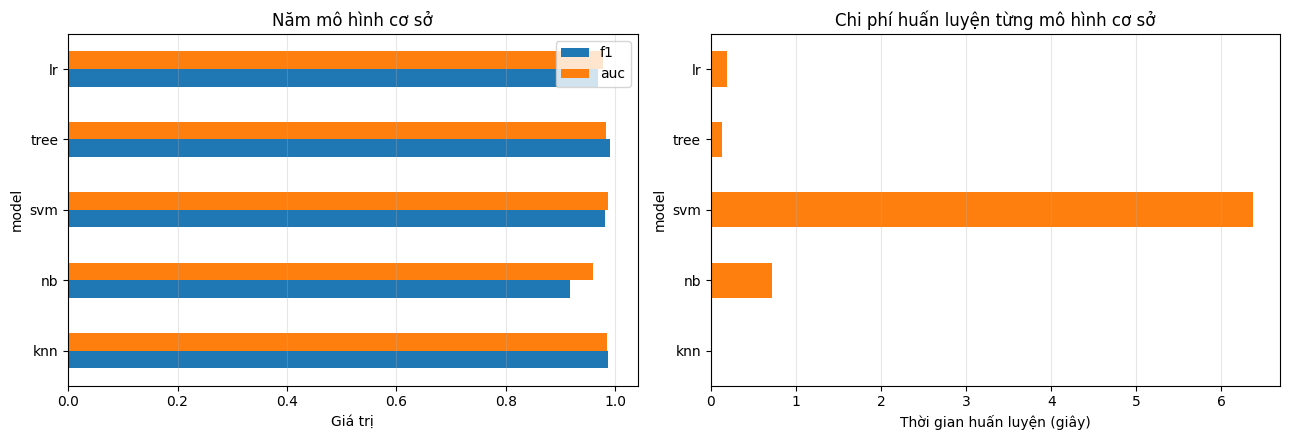

In [5]:
# Năm mô hình cơ sở, mỗi mô hình dùng đúng siêu tham số tốt nhất đã tìm được
# ở các bài trước của công việc này. Ba trong năm mô hình đến từ chính các bài
# đã học: KNN, Naive Bayes và SVM; thêm cây quyết định và hồi quy logistic để
# tăng tính đa dạng về bản chất thuật toán.
bases = make_bases()
rows, preds, probs = [], {}, {}
for tag, m in bases:
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    pr = m.predict_proba(X_te)[:, 1]
    preds[tag], probs[tag] = yp, pr
    r = evaluate(y_te, yp, pr, tag)
    r["fit_s"] = tf
    rows.append(r)

base_df = pd.DataFrame(rows).set_index("model").round(4)
print(base_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])

BASE_BEST = base_df["f1"].idxmax()
print(f"\n→ Mô hình cơ sở tốt nhất: {BASE_BEST} "
      f"(F1 = {base_df.loc[BASE_BEST, 'f1']:.4f})")
print(f"→ Mô hình cơ sở yếu nhất: {base_df['f1'].idxmin()} "
      f"(F1 = {base_df['f1'].min():.4f})")
print(f"→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: "
      f"{base_df['f1'].max() - base_df['f1'].min():.4f}")
print(BASE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
base_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Năm mô hình cơ sở")
axes[0].grid(axis="x", alpha=.3)
base_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện từng mô hình cơ sở")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tính Đa Dạng – Điều Kiện Cần Để Ensemble Có Lợi

Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):
nb ↔ tree     0.1070
nb ↔ svm      0.1048
knn ↔ nb      0.1040
nb ↔ lr       0.1028
knn ↔ lr      0.0405
tree ↔ lr     0.0391
svm ↔ lr      0.0357
knn ↔ svm     0.0180
svm ↔ tree    0.0178
knn ↔ tree    0.0166

Bất đồng trung bình: 0.0586
Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: 0.8660
Trần số lý tưởng (oracle accuracy): 0.9946
   → so với mô hình cơ sở tốt nhất: 0.9878
   → khoảng trống mà ensemble có thể khai thác: +0.0068

Nhận xét: bất đồng trung bình 5,86%, cao gấp ba lần bộ dữ liệu của CV4.1,
và cả năm mô hình chỉ đồng thuận ở 86,6% số mẫu. Dữ liệu này đa dạng hơn —
điều kiện tốt hơn cho ensemble.
Trần số lý tưởng 0,9946 so với 0,9935 của mô hình cơ sở tốt nhất: khoảng
trống khoảng 0,001. Vẫn hẹp, nhưng rộng hơn CV4.1.
Các cặp bất đồng nhiều nhất đều liên quan tới Naive Bayes (khoảng 10%), cho
thấy nó nhìn dữ liệu theo cách rất khác bốn mô hình còn lại.


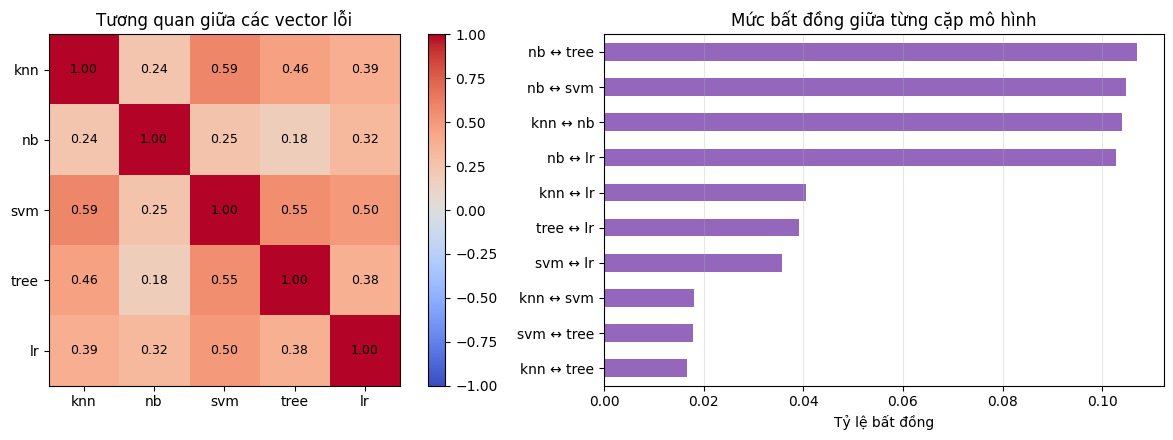

In [6]:
# Ensemble chỉ có lợi khi các mô hình cơ sở mắc lỗi KHÁC NHAU. Nếu cả năm mô
# hình cùng đúng và cùng sai ở những mẫu giống nhau thì việc kết hợp chúng
# không thêm thông tin gì.
#
# Ta đo tính đa dạng bằng ba cách:
#   1. Tỷ lệ bất đồng giữa từng cặp mô hình
#   2. Tương quan giữa các vector lỗi
#   3. "Trần số lý tưởng" (oracle): độ chính xác nếu luôn chọn được mô hình
#      đúng cho mỗi mẫu — đây là giới hạn trên mà không ensemble nào vượt được
tags = list(preds)
dis = {}
for i, a in enumerate(tags):
    for b in tags[i + 1:]:
        dis[f"{a} ↔ {b}"] = (preds[a] != preds[b]).mean()
dis_s = pd.Series(dis).sort_values(ascending=False).round(4)
print("Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):")
print(dis_s.to_string())
print(f"\nBất đồng trung bình: {dis_s.mean():.4f}")

all_agree = np.all([preds[t] == preds[tags[0]] for t in tags], axis=0)
any_right = np.any([preds[t] == y_te for t in tags], axis=0)
print(f"Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: {all_agree.mean():.4f}")
print(f"Trần số lý tưởng (oracle accuracy): {any_right.mean():.4f}")
print(f"   → so với mô hình cơ sở tốt nhất: "
      f"{base_df.loc[BASE_BEST, 'acc']:.4f}")
print(f"   → khoảng trống mà ensemble có thể khai thác: "
      f"{any_right.mean() - base_df.loc[BASE_BEST, 'acc']:+.4f}")
print(DIVERSITY_COMMENT)

err = pd.DataFrame({t: (preds[t] != y_te).astype(int) for t in tags})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
C = err.corr().values
im = axes[0].imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(tags)), tags)
axes[0].set_yticks(range(len(tags)), tags)
axes[0].set_title("Tương quan giữa các vector lỗi")
for i in range(len(tags)):
    for j in range(len(tags)):
        axes[0].text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=axes[0], fraction=.046)

dis_s.sort_values().plot.barh(ax=axes[1], color="tab:purple")
axes[1].set_xlabel("Tỷ lệ bất đồng")
axes[1].set_title("Mức bất đồng giữa từng cặp mô hình")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A4. Hard Voting & Soft Voting

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
Hard Voting              0.9820  0.9819  0.9926  0.9872    0.9783  0.9892   
Soft Voting              0.9834  0.9830  0.9934  0.9882    0.9800  0.9929   
Soft Voting có trọng số  0.9822  0.9811  0.9937  0.9874    0.9785  0.9930   

                          fit_s  
model                            
Hard Voting              9.6595  
Soft Voting              8.6890  
Soft Voting có trọng số  7.6138  

Mô hình cơ sở tốt nhất (tree) có F1 = 0.9913
   Hard Voting                F1 = 0.9872  (-0.0041 so với mô hình cơ sở tốt nhất)
   Soft Voting                F1 = 0.9882  (-0.0031 so với mô hình cơ sở tốt nhất)
   Soft Voting có trọng số    F1 = 0.9874  (-0.0039 so với mô hình cơ sở tốt nhất)

Nhận xét: Soft Voting (0,9882) và Hard Voting (0,9872) đều THẤP HƠN cây
quyết định đơn lẻ (0,9913). Đây là hiện tượng cần hiểu rõ: voting lấy trung


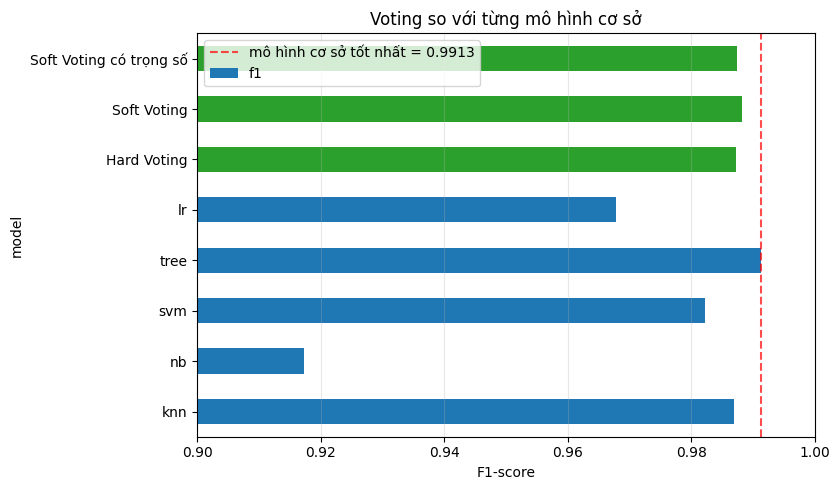

In [7]:
# Voting là cách kết hợp đơn giản nhất:
#   hard voting : mỗi mô hình bỏ một phiếu cho nhãn nó dự đoán, lấy đa số
#   soft voting : lấy trung bình xác suất của các mô hình rồi mới quyết định
#
# Soft voting thường tốt hơn vì nó dùng được mức độ tự tin: một mô hình "chắc
# 95%" có ảnh hưởng lớn hơn một mô hình "chắc 51%". Nhưng nó đòi hỏi mọi mô
# hình cơ sở phải có predict_proba — đó là lý do SVM trong bài này phải đặt
# probability=True, và vì thế huấn luyện chậm hơn nhiều.
#
# Có thể gán trọng số khác nhau cho từng mô hình. Ở đây ta thử gán trọng số 2
# cho SVM và 1 cho bốn mô hình còn lại.
rows = []
for tag, kw in [("Hard Voting", dict(voting="hard")),
                ("Soft Voting", dict(voting="soft")),
                ("Soft Voting có trọng số", dict(voting="soft",
                                                 weights=VOTE_WEIGHTS))]:
    m = VotingClassifier(estimators=make_bases(), n_jobs=-1, **kw)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    # hard voting không có predict_proba → dùng tỷ lệ phiếu làm điểm xếp hạng
    sc = (np.mean([preds[t] for t in tags], axis=0) if kw["voting"] == "hard"
          else m.predict_proba(X_te)[:, 1])
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)

vote_df = pd.DataFrame(rows).set_index("model").round(4)
print(vote_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nMô hình cơ sở tốt nhất ({BASE_BEST}) có F1 = "
      f"{base_df.loc[BASE_BEST, 'f1']:.4f}")
for nm, v in vote_df.iterrows():
    d = v["f1"] - base_df.loc[BASE_BEST, "f1"]
    print(f"   {nm:26s} F1 = {v['f1']:.4f}  ({d:+.4f} so với mô hình cơ sở tốt nhất)")
print(VOTE_COMMENT)

ax = pd.concat([base_df[["f1"]], vote_df[["f1"]]])["f1"].plot.barh(
    figsize=(8.5, 5), color=["tab:blue"] * len(base_df) + ["tab:green"] * len(vote_df))
ax.axvline(base_df["f1"].max(), color="red", ls="--", alpha=.7,
           label=f"mô hình cơ sở tốt nhất = {base_df['f1'].max():.4f}")
ax.set_xlabel("F1-score")
ax.set_title("Voting so với từng mô hình cơ sở")
ax.set_xlim(VOTE_XLIM)
ax.legend()
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Stacking Với Meta-Learner

In [8]:
# Stacking thay phép lấy trung bình bằng một mô hình HỌC CÁCH kết hợp. Quy
# trình: dùng cross-validation nội bộ để sinh dự đoán out-of-fold của từng mô
# hình cơ sở, rồi huấn luyện một meta-learner trên chính các dự đoán đó.
#
# Dùng dự đoán out-of-fold là điều bắt buộc: nếu lấy dự đoán của mô hình cơ sở
# trên dữ liệu mà nó đã được huấn luyện, các con số sẽ lạc quan giả tạo và
# meta-learner học sai.
#
# passthrough=True cho meta-learner nhận thêm cả đặc trưng GỐC, không chỉ dự
# đoán của các mô hình cơ sở — xem chú thích của make_meta() về việc vì sao
# khi đó bắt buộc phải chuẩn hóa.
rows = []
models = {}
for tag, pt in [("Stacking (meta=LR)", False),
                ("Stacking (meta=LR, passthrough)", True)]:
    m = StackingClassifier(
        estimators=make_bases(), final_estimator=make_meta(),
        cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
        passthrough=pt, n_jobs=-1)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    sc = m.predict_proba(X_te)[:, 1]
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)
    models[tag] = m

stack_df = pd.DataFrame(rows).set_index("model").round(4)
print(stack_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nSo sánh nhanh:")
print(f"   Mô hình cơ sở tốt nhất : {base_df.loc[BASE_BEST, 'f1']:.4f}")
print(f"   Soft Voting            : {vote_df.loc['Soft Voting', 'f1']:.4f}")
print(f"   Stacking tốt nhất      : {stack_df['f1'].max():.4f}")
print(f"\nChi phí: Stacking mất {stack_df['fit_s'].max():.1f}s, "
      f"gấp khoảng {stack_df['fit_s'].max() / base_df['fit_s'].sum():.1f} lần "
      f"tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ "
      f"({base_df['fit_s'].sum():.1f}s) — vì cross-validation nội bộ phải huấn "
      f"luyện lại mỗi mô hình {CV_FOLDS} lần.")
print(STACK_COMMENT)

STACK_BEST = stack_df["f1"].idxmax()
stack_model = models["Stacking (meta=LR)"]


                                    acc    prec     rec      f1  f1_macro  \
model                                                                       
Stacking (meta=LR)               0.9862  0.9853  0.9951  0.9902    0.9834   
Stacking (meta=LR, passthrough)  0.9858  0.9850  0.9949  0.9899    0.9829   

                                    auc    fit_s  
model                                             
Stacking (meta=LR)               0.9938  19.7182  
Stacking (meta=LR, passthrough)  0.9944  21.5362  

So sánh nhanh:
   Mô hình cơ sở tốt nhất : 0.9913
   Soft Voting            : 0.9882
   Stacking tốt nhất      : 0.9902

Chi phí: Stacking mất 21.5s, gấp khoảng 2.9 lần tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ (7.4s) — vì cross-validation nội bộ phải huấn luyện lại mỗi mô hình 5 lần.

Nhận xét: Stacking đạt 0,9902, cao hơn Soft Voting (0,9882) đúng như dự
đoán — meta-learner học được rằng không nên tin Naive Bayes nhiều. Nhưng nó
vẫn chưa bằng cây quyết định đơn lẻ (0,9

### A6. Meta-Learner Tin Mô Hình Nào?

Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:
knn     1.9569
tree    1.9008
svm     1.0276
nb      0.2719
lr     -0.5243

Hệ số chặn (intercept): 1.8454

Đối chiếu với F1 của từng mô hình cơ sở:
      hệ số meta  F1 cơ sở
knn       1.9569    0.9869
lr       -0.5243    0.9678
nb        0.2719    0.9173
svm       1.0276    0.9822
tree      1.9008    0.9913

⚠ Có 1 mô hình nhận hệ số ÂM: ['lr'] — meta-learner dùng chúng làm tín hiệu ngược.

Nhận xét: hệ số cho thấy meta-learner tin KNN (1,96) và cây quyết định
(1,90) gần như bằng nhau, SVM thấp hơn (1,03), Naive Bayes rất thấp (0,27).
Đáng chú ý nhất: hồi quy logistic nhận hệ số ÂM (-0,52). Meta-learner dùng
nó làm tín hiệu NGƯỢC — khi hồi quy logistic nói "mã độc" thì meta-learner
lại nghiêng về "lành tính".
Giải thích hợp lý: hồi quy logistic chỉ dựng được ranh giới tuyến tính, nên
nó sai một cách CÓ HỆ THỐNG ở những vùng nhất định của không gian đặc trưng.
Sai có hệ thống thì dự đoán được, và meta-learner kha

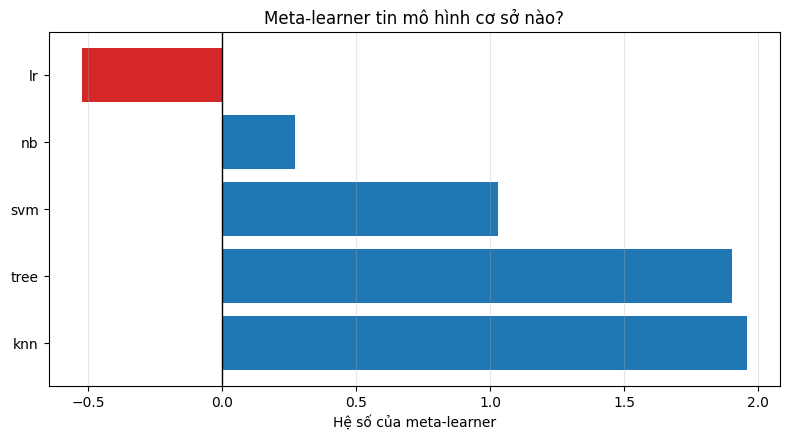

In [9]:
# Hệ số của meta-learner cho biết nó TIN mô hình nào. Đây là thứ mà voting
# không có: voting gán trọng số cố định do người dùng chọn, còn stacking HỌC
# trọng số từ dữ liệu.
#
# Hệ số ÂM đặc biệt đáng chú ý: nó nghĩa là meta-learner dùng mô hình đó như
# một tín hiệu NGƯỢC — khi mô hình ấy nói "tấn công" thì meta-learner lại
# nghiêng về "bình thường". Điều này xảy ra khi một mô hình cơ sở sai một cách
# có hệ thống ở những vùng dữ liệu nhất định.
coef = stack_model.final_estimator_["lr"].coef_.ravel()
intercept = stack_model.final_estimator_["lr"].intercept_[0]
coef_s = pd.Series(coef, index=tags).sort_values(ascending=False).round(4)

print("Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:")
print(coef_s.to_string())
print(f"\nHệ số chặn (intercept): {intercept:.4f}")
print(f"\nĐối chiếu với F1 của từng mô hình cơ sở:")
cmp2 = pd.DataFrame({"hệ số meta": coef_s,
                     "F1 cơ sở": base_df["f1"]}).round(4)
print(cmp2.to_string())
neg = coef_s[coef_s < 0]
if len(neg):
    print(f"\n⚠ Có {len(neg)} mô hình nhận hệ số ÂM: {list(neg.index)} — "
          f"meta-learner dùng chúng làm tín hiệu ngược.")
else:
    print("\nKhông mô hình nào nhận hệ số âm.")
print(META_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in coef_s.values]
ax.barh(coef_s.index, coef_s.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Hệ số của meta-learner")
ax.set_title("Meta-learner tin mô hình cơ sở nào?")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Tổng Hợp & So Sánh Với Random Forest

                                   prec     rec      f1  f1_macro     auc    fit_s
model                                                                             
Random Forest (200 cây)          0.9895  0.9980  0.9937    0.9894  0.9982   0.8478
Cơ sở: tree                      0.9867  0.9960  0.9913    0.9853  0.9825   0.1381
Stacking (meta=LR)               0.9853  0.9951  0.9902    0.9834  0.9938  19.7182
Stacking (meta=LR, passthrough)  0.9850  0.9949  0.9899    0.9829  0.9944  21.5362
Soft Voting                      0.9830  0.9934  0.9882    0.9800  0.9929   8.6890
Soft Voting có trọng số          0.9811  0.9937  0.9874    0.9785  0.9930   7.6138
Hard Voting                      0.9819  0.9926  0.9872    0.9783  0.9892   9.6595
Cơ sở: knn                       0.9858  0.9880  0.9869    0.9780  0.9854   0.0128
Cơ sở: svm                       0.9739  0.9906  0.9822    0.9695  0.9871   6.3690
Cơ sở: lr                        0.9667  0.9689  0.9678    0.9459  0.9780   0.1937
Cơ s


Confusion matrix của Stacking: TN=1438 FP=52 FN=17 TP=3485

              precision    recall  f1-score   support

      Benign     0.9883    0.9651    0.9766      1490
     Malware     0.9853    0.9951    0.9902      3502

    accuracy                         0.9862      4992
   macro avg     0.9868    0.9801    0.9834      4992
weighted avg     0.9862    0.9862    0.9861      4992


Nhận xét: người thắng là RANDOM FOREST (0,9937), vượt cả Stacking (0,9902)
và mọi mô hình khác.
Kết quả này đáng để suy ngẫm: một ensemble gồm năm thuật toán KHÁC NHAU, mỗi
thuật toán đã được dò siêu tham số riêng ở các bài trước, lại thua một
Random Forest dùng tham số mặc định — vốn chỉ là 200 bản sao của CÙNG một
thuật toán cây quyết định.
Lý do: Random Forest tạo đa dạng bằng bootstrap mẫu và chọn ngẫu nhiên tập
đặc trưng ở mỗi nhánh, nên 200 cây của nó đa dạng hơn hẳn năm thuật toán
của ta. Thêm nữa nó huấn luyện trong khoảng 1 giây, nhanh hơn Stacking gần
20 lần.


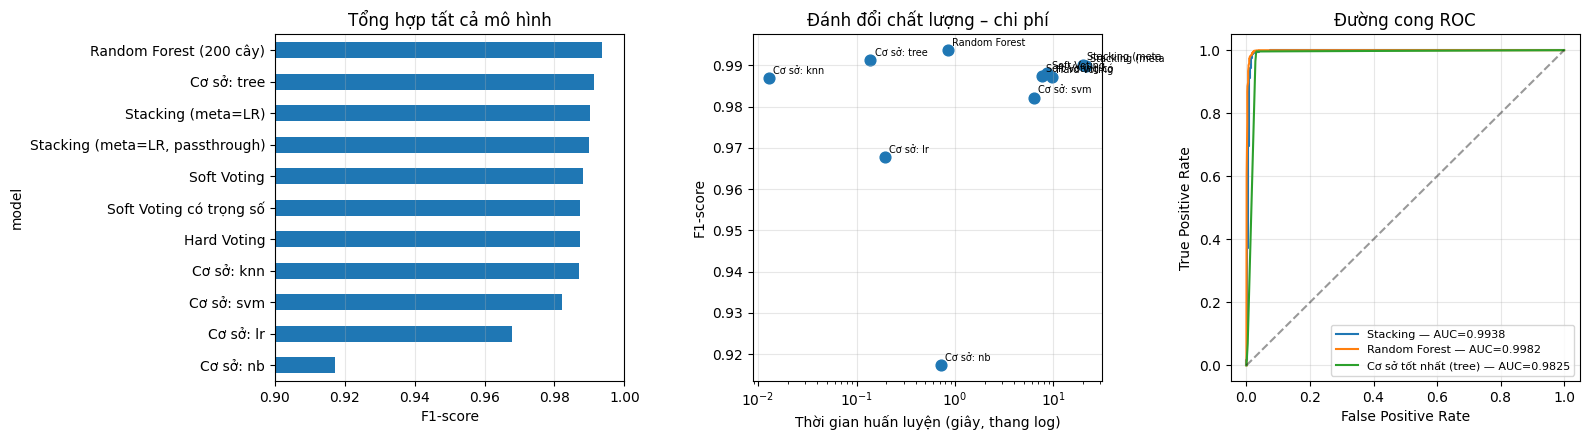

In [10]:
# Tổng hợp tất cả: năm mô hình cơ sở, ba kiểu voting, hai kiểu stacking, và
# Random Forest làm mốc so sánh. Random Forest bản thân cũng là một ensemble
# (bagging 200 cây) nên đây là phép so sánh công bằng giữa hai triết lý:
# kết hợp nhiều thuật toán KHÁC NHAU so với kết hợp nhiều bản sao của CÙNG
# một thuật toán.
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
rf_t = time.perf_counter() - t0
rf_sc = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_sc, "Random Forest (200 cây)")
rf_res["fit_s"] = rf_t

all_df = pd.concat([
    base_df.rename(index=lambda s: "Cơ sở: " + s),
    vote_df, stack_df,
    pd.DataFrame([rf_res]).set_index("model"),
]).round(4)
print(all_df[["prec", "rec", "f1", "f1_macro", "auc", "fit_s"]].sort_values(
    "f1", ascending=False).to_string())

WINNER = all_df["f1"].idxmax()
print(f"\n→ Mô hình tốt nhất theo F1: {WINNER} ({all_df.loc[WINNER, 'f1']:.4f})")
print(f"→ Random Forest đứng thứ "
      f"{int((all_df['f1'] > rf_res['f1']).sum()) + 1}/{len(all_df)}")

yp_st = stack_model.predict(X_te)
cm = confusion_matrix(y_te, yp_st)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix của Stacking: TN={tn} FP={fp} FN={fn} TP={tp}")
print("\n" + classification_report(y_te, yp_st, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
all_df["f1"].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel("F1-score")
axes[0].set_title("Tổng hợp tất cả mô hình")
axes[0].set_xlim(VOTE_XLIM)
axes[0].grid(axis="x", alpha=.3)

axes[1].scatter(all_df["fit_s"], all_df["f1"], s=60)
for nm, v in all_df.iterrows():
    axes[1].annotate(nm[:14], (v["fit_s"], v["f1"]), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện (giây, thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Đánh đổi chất lượng – chi phí")
axes[1].grid(alpha=.3)

for nm, sc in [("Stacking", stack_model.predict_proba(X_te)[:, 1]),
               ("Random Forest", rf_sc),
               (f"Cơ sở tốt nhất ({BASE_BEST})", probs[BASE_BEST])]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

Chạy 5-fold cross-validation mất 133.6 giây

F1 từng fold : [0.9913 0.9906 0.991  0.99   0.9895]
F1 trung bình: 0.9905 ± 0.0006
F1 của một lần chia train/test ở A7: 0.9902

Nhận xét: F1 trung bình 0,9905 ± 0,0006 — ổn định và khớp với kết quả một
lần chia ở A5. Con số này vẫn thấp hơn Random Forest, nên kết luận ở A7
không phải do may mắn của một lần chia.


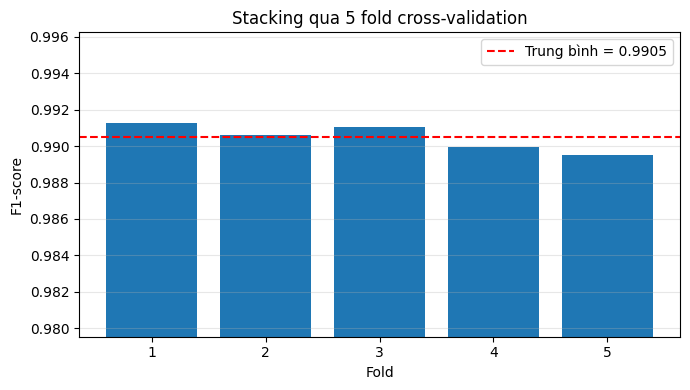

In [11]:
# Toàn bộ stacking — gồm năm Pipeline cơ sở và meta-learner — nằm trong một
# đối tượng duy nhất, nên đưa thẳng vào cross_val_score là an toàn: mỗi fold
# sẽ fit lại tất cả, kể cả các bước tiền xử lý.
#
# Lưu ý về chi phí: mỗi fold phải huấn luyện 5 mô hình cơ sở × 5 fold nội bộ
# cộng một lần fit cuối, nên 5-fold cross-validation ở đây tốn thời gian gấp
# nhiều lần các bài trước.
model_cv = StackingClassifier(
    estimators=make_bases(), final_estimator=make_meta(),
    cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    n_jobs=-1)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
scores = cross_val_score(model_cv, X_raw, y, cv=cv, scoring="f1", n_jobs=1)
print(f"Chạy {CV_FOLDS}-fold cross-validation mất {time.perf_counter()-t0:.1f} giây")

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: "
      f"{stack_df.loc['Stacking (meta=LR)', 'f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.01, max(scores) + 0.005)
ax.set_title(f"Stacking qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Các mô hình cơ sở chênh lệch rõ hơn bộ dữ liệu của CV4.1: từ 0,917 (Naive Bayes) tới 0,991 (cây quyết định).
2. Bất đồng trung bình 5,86% — cao gấp ba lần CV4.1, điều kiện tốt hơn cho ensemble.
3. **Voting KÉM HƠN cây quyết định đơn lẻ** (0,9882 so với 0,9913): Naive Bayes yếu kéo trung bình xuống.
4. Stacking 0,9902 — cao hơn voting đúng như dự đoán, nhưng vẫn chưa bằng cây quyết định đơn lẻ.
5. Meta-learner gán hồi quy logistic hệ số **ÂM** (-0,52), dùng nó làm tín hiệu ngược.
6. **Random Forest đơn lẻ (0,9937) thắng toàn bộ**, kể cả ensemble của năm thuật toán đã dò siêu tham số, và nhanh hơn Stacking gần 20 lần.

**Câu hỏi thảo luận**

1. Voting cho kết quả thấp hơn mô hình cơ sở tốt nhất. Hãy giải thích cơ chế dẫn tới điều đó, và nêu điều kiện cần để voting thực sự có lợi.
2. Meta-learner gán hồi quy logistic hệ số âm. Hãy giải thích ý nghĩa của hệ số âm, và vì sao một mô hình sai "có hệ thống" lại hữu ích hơn một mô hình sai ngẫu nhiên.
3. Random Forest là ensemble của 200 cây CÙNG loại, còn Stacking là ensemble của 5 thuật toán KHÁC loại. Vì sao cái thứ nhất lại đa dạng hơn? Hãy nêu hai cơ chế tạo đa dạng của Random Forest.
4. Nếu không bọc `StandardScaler` trong meta-learner thì `Stacking passthrough` cho F1 = 0. Hãy giải thích nguyên nhân dựa trên biên độ của đặc trưng PE header.
5. Vì sao `cv` trong `StackingClassifier` phải dùng dự đoán out-of-fold? Nếu dùng dự đoán của mô hình cơ sở trên chính dữ liệu nó đã học thì meta-learner sẽ học sai điều gì?
6. Dựa trên kết quả bài này, hãy viết một khuyến nghị ngắn cho đồng nghiệp đang định xây ensemble: nên thử gì trước, và dấu hiệu nào cho biết nên dừng.
7. Sau năm bài trên cùng bộ PE header, hãy chọn một mô hình để triển khai và giải thích, có tính tới việc một sản phẩm antivirus cần huấn luyện lại thường xuyên trên dữ liệu mới.
